# ALY 6110: Data Management and Big Data
## Module 2 Group Assignment - Querying at Scale with Google BigQuery

| | |
|---|---|
| **Group** | Group 8 |
| **Members** | Haonan Zhang, Rabiat Blessing Ibrahim, Jennifer Flora Bastian |
| **University** | Northeastern University |
| **Professor** | Arash Shamseddini |
| **Date** | June 2, 2026 |

---
## Dataset
`bigquery-public-data.new_york.tlc_yellow_trips_2015` - all six queries use the same dataset.

## Queries Overview
| Query | Member | Business Question |
|---|---|---|
| Q1 | Haonan Zhang | How did yellow taxi demand and revenue change across 2015? |
| Q2 | Haonan Zhang | Do longer yellow taxi trips receive better tips? |
| Q3 | Rabiat Blessing Ibrahim | Do credit card and cash passengers behave differently by hour? |
| Q4 | Rabiat Blessing Ibrahim | When are taxi trips most profitable per mile? |
| Q5 | Jennifer Flora Bastian | Which hours are most popular for solo vs group taxi trips? |
| Q6 | Jennifer Flora Bastian | How do weekday and weekend taxi trips differ in fare, distance, and tipping behaviour? |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import io

TEAL='#0D9488'; AMBER='#F59E0B'; PURPLE='#A78BFA'
NAVY='#0D1B2A'; PANEL='#1E293B'; MUTED='#94A3B8'
WHITE='#FFFFFF'; GREEN='#22C55E'; CORAL='#F87171'

plt.rcParams.update({
    'figure.facecolor': NAVY, 'axes.facecolor': PANEL,
    'axes.edgecolor': '#475569', 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': WHITE, 'grid.color': '#334155',
    'grid.linestyle': '--', 'grid.alpha': 0.5,
    'axes.titlecolor': WHITE, 'font.family': 'sans-serif'
})
print('Setup complete.')

Setup complete.


---
# HAONAN ZHANG - Queries 1 & 2
---
## Query 1: Monthly Trip Demand and Revenue (2015)
**Business Question:** How did yellow taxi demand and revenue change across 2015?
```sql
SELECT
  EXTRACT(MONTH FROM pickup_datetime) AS trip_month,
  COUNT(*) AS trip_count,
  ROUND(SUM(total_amount), 2) AS total_revenue,
  ROUND(AVG(total_amount), 2) AS avg_trip_total
FROM `bigquery-public-data.new_york.tlc_yellow_trips_2015`
WHERE pickup_datetime IS NOT NULL AND total_amount > 0
GROUP BY trip_month
ORDER BY trip_month;
```

In [2]:
q1_data = """trip_month,trip_count,total_revenue,avg_trip_total
1,12743725,192658845.19,15.12
2,12445198,191788628.91,15.41
3,13345745,211688002.89,15.86
4,13066325,209696315.69,16.05
5,13153195,216190945.07,16.44
6,12320013,201908395.06,16.39
7,11557502,186684599.44,16.15
8,11124770,179780402.55,16.16
9,11219525,185110805.39,16.50
10,12309635,203482828.29,16.53
11,11307223,185204156.54,16.38
12,11454832,188239477.40,16.43"""

df_q1 = pd.read_csv(io.StringIO(q1_data))
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
df_q1['month_name'] = months

total_trips   = df_q1['trip_count'].sum()
total_revenue = df_q1['total_revenue'].sum()
print(f'Total trips 2015  : {total_trips:,.0f} ({total_trips/1e6:.1f}M)')
print(f'Total revenue 2015: ${total_revenue/1e9:.2f}B')
print(f'Peak month        : {months[df_q1["trip_count"].idxmax()]} - {df_q1["trip_count"].max():,} trips')
print(f'Lowest month      : {months[df_q1["trip_count"].idxmin()]} - {df_q1["trip_count"].min():,} trips')
print(f'Avg trip rose from: ${df_q1["avg_trip_total"].min():.2f} ({months[df_q1["avg_trip_total"].idxmin()]}) to ${df_q1["avg_trip_total"].max():.2f} ({months[df_q1["avg_trip_total"].idxmax()]})')

Total trips 2015  : 146,047,688 (146.0M)
Total revenue 2015: $2.35B
Peak month        : Mar - 13,345,745 trips
Lowest month      : Aug - 11,124,770 trips
Avg trip rose from: $15.12 (Jan) to $16.53 (Oct)


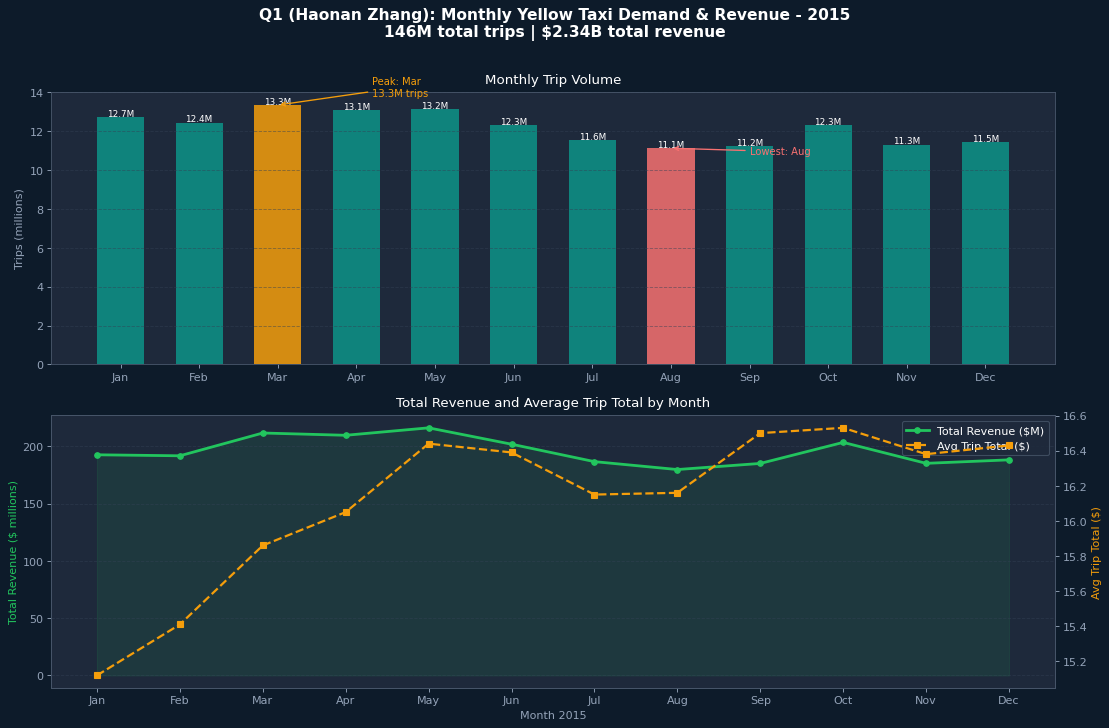

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
fig.suptitle('Q1 (Haonan Zhang): Monthly Yellow Taxi Demand & Revenue - 2015\n146M total trips | $2.34B total revenue',
             fontsize=14, fontweight='bold', color=WHITE, y=1.01)

# Chart 1: Trip count
ax1 = axes[0]
peak_idx = df_q1['trip_count'].idxmax()
low_idx  = df_q1['trip_count'].idxmin()
bar_colors = [AMBER if i==peak_idx else CORAL if i==low_idx else TEAL for i in range(12)]
bars = ax1.bar(df_q1['month_name'], df_q1['trip_count']/1e6, color=bar_colors, alpha=0.85, width=0.6)
ax1.set_title('Monthly Trip Volume', fontsize=12, color=WHITE, pad=8)
ax1.set_ylabel('Trips (millions)', color=MUTED)
ax1.grid(True, axis='y')
for bar, val in zip(bars, df_q1['trip_count']/1e6):
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
             f'{val:.1f}M', ha='center', fontsize=8, color=WHITE)
ax1.annotate(f'Peak: Mar\n{df_q1.loc[peak_idx,"trip_count"]/1e6:.1f}M trips',
             xy=(peak_idx, df_q1.loc[peak_idx,'trip_count']/1e6),
             xytext=(peak_idx+1.2, 13.8), color=AMBER, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.2))
ax1.annotate(f'Lowest: Aug',
             xy=(low_idx, df_q1.loc[low_idx,'trip_count']/1e6),
             xytext=(low_idx+1, 10.8), color=CORAL, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=CORAL, lw=1.2))

# Chart 2: Revenue + avg trip dual axis
ax2 = axes[1]
ax2b = ax2.twinx()
ax2b.tick_params(colors=MUTED)
ax2b.spines['right'].set_color('#475569')
l1, = ax2.plot(df_q1['month_name'], df_q1['total_revenue']/1e6, color=GREEN,
               lw=2.5, marker='o', ms=5, label='Total Revenue ($M)')
ax2.fill_between(range(12), df_q1['total_revenue']/1e6, alpha=0.1, color=GREEN)
l2, = ax2b.plot(df_q1['month_name'], df_q1['avg_trip_total'], color=AMBER,
                lw=2, marker='s', ms=5, linestyle='--', label='Avg Trip Total ($)')
ax2.set_title('Total Revenue and Average Trip Total by Month', fontsize=12, color=WHITE, pad=8)
ax2.set_ylabel('Total Revenue ($ millions)', color=GREEN)
ax2b.set_ylabel('Avg Trip Total ($)', color=AMBER)
ax2.set_xlabel('Month 2015', color=MUTED)
ax2.grid(True, axis='y')
ax2.legend([l1,l2],[l1.get_label(),l2.get_label()],
           facecolor=PANEL, edgecolor='#475569', labelcolor=WHITE)

plt.tight_layout()
plt.savefig('query1_haonan.png', dpi=150, bbox_inches='tight', facecolor=NAVY)
plt.show()

---
## Query 2: Tip Percentage by Trip Distance Group (2015)
**Business Question:** Do longer yellow taxi trips receive better tips?
```sql
SELECT
  CASE
    WHEN trip_distance < 1 THEN 'Short: Under 1 mile'
    WHEN trip_distance >= 1 AND trip_distance < 3 THEN 'Medium: 1-3 miles'
    WHEN trip_distance >= 3 AND trip_distance < 10 THEN 'Long: 3-10 miles'
    ELSE 'Very Long: 10+ miles'
  END AS distance_group,
  COUNT(*) AS trip_count,
  ROUND(AVG(trip_distance), 2) AS avg_distance,
  ROUND(AVG(tip_amount), 2) AS avg_tip,
  ROUND(AVG(total_amount), 2) AS avg_total_amount,
  ROUND(AVG(tip_amount / NULLIF(total_amount, 0)) * 100, 2) AS avg_tip_percentage
FROM `bigquery-public-data.new_york.tlc_yellow_trips_2015`
WHERE trip_distance > 0 AND total_amount > 0 AND tip_amount >= 0
GROUP BY distance_group
ORDER BY avg_distance;
```

In [4]:
q2_data = """distance_group,trip_count,avg_distance,avg_tip,avg_total_amount,avg_tip_percentage
Short: Under 1 mile,32594961,0.68,0.74,7.46,8.93
Medium: 1-3 miles,72544476,1.75,1.26,12.0,9.72
Long: 3-10 miles,31842688,5.09,2.69,23.74,10.02
Very Long: 10+ miles,8161084,211.69,6.05,56.16,10.05"""

df_q2 = pd.read_csv(io.StringIO(q2_data))
order = ['Short: Under 1 mile','Medium: 1-3 miles','Long: 3-10 miles','Very Long: 10+ miles']
df_q2['distance_group'] = pd.Categorical(df_q2['distance_group'], categories=order, ordered=True)
df_q2 = df_q2.sort_values('distance_group').reset_index(drop=True)
short_labels = ['<1mi','1-3mi','3-10mi','10+mi']

print('Query 2 Results:')
print(df_q2[['distance_group','trip_count','avg_tip','avg_total_amount','avg_tip_percentage']].to_string(index=False))
print()
print('NOTE: avg_distance of 211.69mi for Very Long group indicates outlier rows')
print('      (extreme GPS errors or data entry issues) - flagged as data quality finding')
print(f'Total trips across all groups: {df_q2["trip_count"].sum()/1e6:.1f}M')

Query 2 Results:
      distance_group  trip_count  avg_tip  avg_total_amount  avg_tip_percentage
 Short: Under 1 mile    32594961     0.74              7.46                8.93
   Medium: 1-3 miles    72544476     1.26             12.00                9.72
    Long: 3-10 miles    31842688     2.69             23.74               10.02
Very Long: 10+ miles     8161084     6.05             56.16               10.05

NOTE: avg_distance of 211.69mi for Very Long group indicates outlier rows
      (extreme GPS errors or data entry issues) - flagged as data quality finding
Total trips across all groups: 145.1M


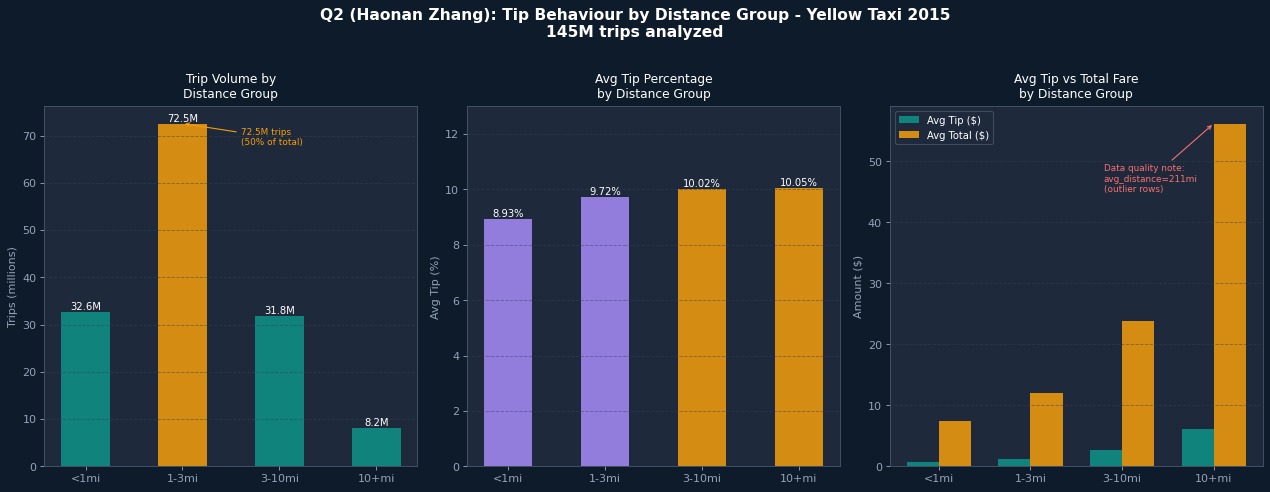

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Q2 (Haonan Zhang): Tip Behaviour by Distance Group - Yellow Taxi 2015\n145M trips analyzed',
             fontsize=14, fontweight='bold', color=WHITE, y=1.02)

# Chart 1: Trip count
ax1 = axes[0]
peak_g = df_q2['trip_count'].idxmax()
bar_colors = [AMBER if i==peak_g else TEAL for i in range(4)]
bars = ax1.bar(short_labels, df_q2['trip_count']/1e6, color=bar_colors, alpha=0.85, width=0.5)
ax1.set_title('Trip Volume by\nDistance Group', fontsize=11, color=WHITE, pad=8)
ax1.set_ylabel('Trips (millions)', color=MUTED)
ax1.grid(True, axis='y')
for bar, val in zip(bars, df_q2['trip_count']/1e6):
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
             f'{val:.1f}M', ha='center', fontsize=9, color=WHITE)
ax1.annotate('72.5M trips\n(50% of total)', xy=(1, df_q2.loc[1,'trip_count']/1e6),
             xytext=(1.6, 68), color=AMBER, fontsize=8,
             arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.0))

# Chart 2: Avg tip %
ax2 = axes[1]
tip_colors = [PURPLE, PURPLE, AMBER, AMBER]
bars2 = ax2.bar(short_labels, df_q2['avg_tip_percentage'], color=tip_colors, alpha=0.85, width=0.5)
ax2.set_title('Avg Tip Percentage\nby Distance Group', fontsize=11, color=WHITE, pad=8)
ax2.set_ylabel('Avg Tip (%)', color=MUTED)
ax2.grid(True, axis='y')
ax2.set_ylim(0, 13)
for bar, val in zip(bars2, df_q2['avg_tip_percentage']):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
             f'{val:.2f}%', ha='center', fontsize=9, color=WHITE)

# Chart 3: Avg tip $ vs avg total
ax3 = axes[2]
x = np.arange(4)
w = 0.35
ax3.bar(x-w/2, df_q2['avg_tip'],         width=w, color=TEAL,  alpha=0.85, label='Avg Tip ($)')
ax3.bar(x+w/2, df_q2['avg_total_amount'], width=w, color=AMBER, alpha=0.85, label='Avg Total ($)')
ax3.set_title('Avg Tip vs Total Fare\nby Distance Group', fontsize=11, color=WHITE, pad=8)
ax3.set_ylabel('Amount ($)', color=MUTED)
ax3.set_xticks(x); ax3.set_xticklabels(short_labels)
ax3.grid(True, axis='y')
ax3.legend(facecolor=PANEL, edgecolor='#475569', labelcolor=WHITE, fontsize=9)
ax3.annotate('Data quality note:\navg_distance=211mi\n(outlier rows)',
             xy=(3, df_q2.loc[3,'avg_total_amount']), xytext=(1.8, 45),
             color=CORAL, fontsize=8,
             arrowprops=dict(arrowstyle='->', color=CORAL, lw=1.0))

plt.tight_layout()
plt.savefig('query2_haonan.png', dpi=150, bbox_inches='tight', facecolor=NAVY)
plt.show()

---
# RABIAT BLESSING IBRAHIM - Queries 3 & 4
---
## Query 3: Hourly Demand by Payment Type
**Business Question:** Do credit card and cash passengers behave differently across hours of the day?
```sql
SELECT
  EXTRACT(HOUR FROM pickup_datetime) AS hour,
  payment_type,
  COUNT(*) AS trip_count,
  ROUND(AVG(fare_amount), 2) AS avg_fare,
  ROUND(AVG(tip_amount), 2) AS avg_tip
FROM `bigquery-public-data.new_york.tlc_yellow_trips_2015`
WHERE fare_amount > 0 AND payment_type IN ('1', '2')
GROUP BY hour, payment_type
ORDER BY hour, payment_type;
```

In [6]:
q3_data = """hour,payment_type,trip_count,avg_fare,avg_tip
0,1,3638512,13.85,2.73
0,2,1914762,12.35,0.0
1,1,2668869,13.3,2.6
1,2,1429154,12.29,0.0
2,1,1934108,13.02,2.52
2,2,1071662,12.45,0.0
3,1,1354762,13.55,2.57
3,2,830883,15.03,0.0
4,1,898238,16.34,3.14
4,2,729972,14.0,0.0
5,1,890141,18.3,3.65
5,2,627522,13.51,0.0
6,1,2058471,14.35,2.81
6,2,1186523,11.39,0.0
7,1,3597301,12.74,2.5
7,2,1791323,11.2,0.0
8,1,4487114,12.76,2.5
8,2,2056403,11.44,0.0
9,1,4410564,12.8,2.54
9,2,2298714,11.4,0.0
10,1,4041504,13.09,2.63
10,2,2573679,11.55,0.0
11,1,4096025,13.33,2.68
11,2,2777379,11.9,0.0
12,1,4258028,13.4,2.69
12,2,2925826,11.88,0.0
13,1,4195962,13.82,2.78
13,2,2956162,12.29,0.0
14,1,4303954,14.36,2.88
14,2,3070626,12.65,0.0
15,1,4080833,14.61,2.94
15,2,2962095,12.75,0.0
16,1,3575503,14.52,3.02
16,2,2569551,12.6,0.0
17,1,4396566,13.79,2.85
17,2,2894003,12.31,0.0
18,1,5488052,12.84,2.66
18,2,3225584,11.66,0.0
19,1,5816986,12.47,3.26
19,2,3167516,11.24,0.0
20,1,5649148,12.71,2.6
20,2,2835531,11.27,0.0
21,1,5617492,13.18,2.7
21,2,2819878,11.42,0.0
22,1,5408055,13.62,2.76
22,2,2715467,11.81,0.0
23,1,4699347,14.03,2.8
23,2,2404610,12.25,0.0"""

df_q3 = pd.read_csv(io.StringIO(q3_data))
df_card = df_q3[df_q3['payment_type']==1].set_index('hour')
df_cash = df_q3[df_q3['payment_type']==2].set_index('hour')
hours = list(range(24))
total_card = df_card['trip_count'].sum()
total_cash = df_cash['trip_count'].sum()
total = total_card + total_cash

# Trip-weighted average fares (each hour counts in proportion to its trips)
card_fare = (df_card['avg_fare'] * df_card['trip_count']).sum() / total_card
cash_fare = (df_cash['avg_fare'] * df_cash['trip_count']).sum() / total_cash

print(f'Credit card: {total_card/total*100:.1f}% - {total_card:,.0f} trips | avg fare ${card_fare:.2f}')
print(f'Cash:        {total_cash/total*100:.1f}% - {total_cash:,.0f} trips | avg fare ${cash_fare:.2f}')
print(f'Fare premium for card payers: ${card_fare-cash_fare:.2f} more per trip (trip-weighted)')
print(f'Highest card tip: 5 AM at ${df_card.loc[5,"avg_tip"]:.2f} (also the hour with the highest card fare, ${df_card.loc[5,"avg_fare"]:.2f})')

Credit card: 63.0% - 91,565,535 trips | avg fare $13.48
Cash:        37.0% - 53,834,825 trips | avg fare $12.01
Fare premium for card payers: $1.47 more per trip (trip-weighted)
Highest card tip: 5 AM at $3.65 (also the hour with the highest card fare, $18.30)


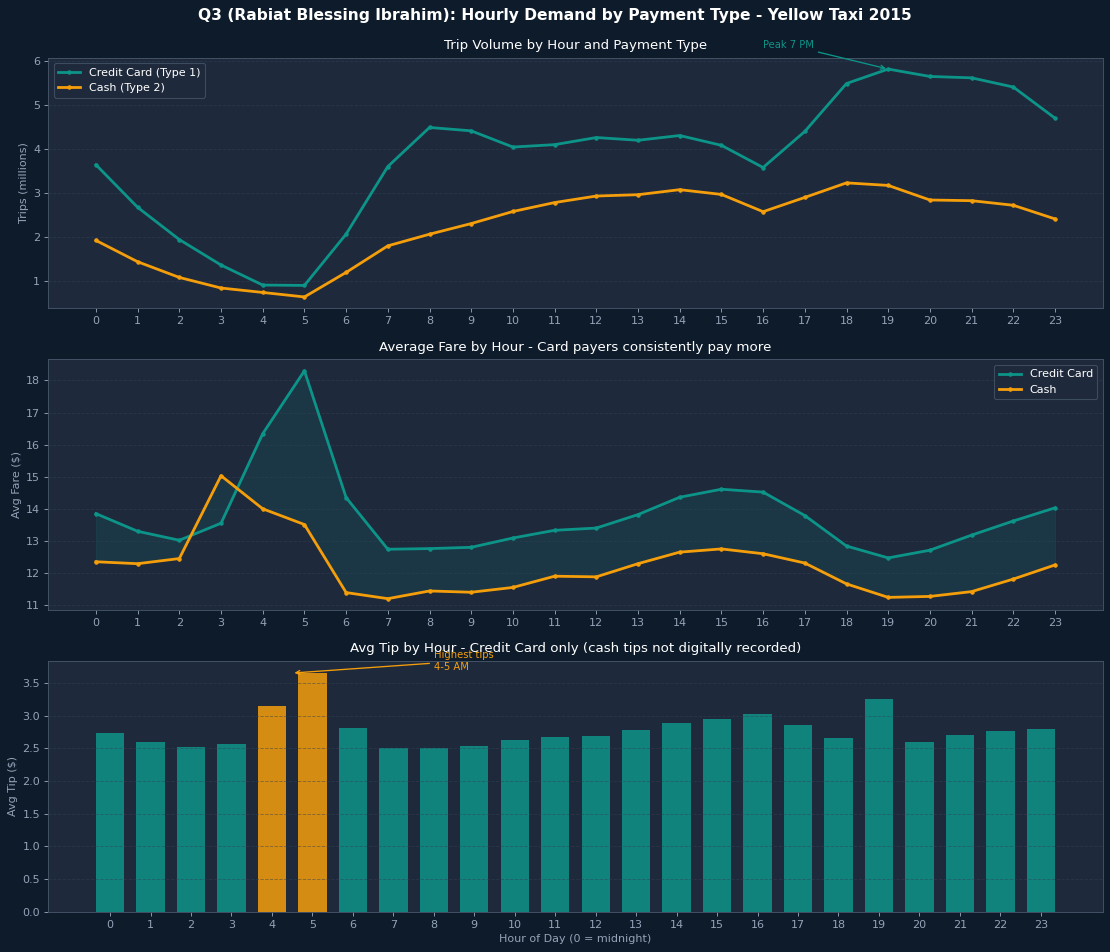

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle('Q3 (Rabiat Blessing Ibrahim): Hourly Demand by Payment Type - Yellow Taxi 2015',
             fontsize=14, fontweight='bold', color=WHITE, y=0.99)

ax1 = axes[0]
ax1.plot(hours, df_card['trip_count']/1e6, color=TEAL,  lw=2.5, marker='o', ms=3, label='Credit Card (Type 1)')
ax1.plot(hours, df_cash['trip_count']/1e6, color=AMBER, lw=2.5, marker='o', ms=3, label='Cash (Type 2)')
ax1.set_title('Trip Volume by Hour and Payment Type', fontsize=12, color=WHITE, pad=8)
ax1.set_ylabel('Trips (millions)', color=MUTED)
ax1.legend(facecolor=PANEL, edgecolor='#475569', labelcolor=WHITE)
ax1.grid(True, axis='y'); ax1.set_xticks(hours)
ax1.annotate('Peak 7 PM', xy=(19, df_card.loc[19,'trip_count']/1e6),
             xytext=(16,6.3), color=TEAL, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=TEAL, lw=1.2))

ax2 = axes[1]
ax2.plot(hours, df_card['avg_fare'], color=TEAL,  lw=2.5, marker='o', ms=3, label='Credit Card')
ax2.plot(hours, df_cash['avg_fare'], color=AMBER, lw=2.5, marker='o', ms=3, label='Cash')
ax2.fill_between(hours, df_card['avg_fare'], df_cash['avg_fare'], alpha=0.12, color=TEAL)
ax2.set_title('Average Fare by Hour - Card payers consistently pay more', fontsize=12, color=WHITE, pad=8)
ax2.set_ylabel('Avg Fare ($)', color=MUTED)
ax2.legend(facecolor=PANEL, edgecolor='#475569', labelcolor=WHITE)
ax2.grid(True, axis='y'); ax2.set_xticks(hours)

ax3 = axes[2]
bar_colors = [AMBER if i in [4,5] else TEAL for i in hours]
ax3.bar(hours, df_card['avg_tip'], color=bar_colors, alpha=0.85, width=0.7)
ax3.set_title('Avg Tip by Hour - Credit Card only (cash tips not digitally recorded)', fontsize=12, color=WHITE, pad=8)
ax3.set_ylabel('Avg Tip ($)', color=MUTED)
ax3.set_xlabel('Hour of Day (0 = midnight)', color=MUTED)
ax3.grid(True, axis='y'); ax3.set_xticks(hours)
ax3.annotate('Highest tips\n4-5 AM', xy=(4.5, 3.65),
             xytext=(8,3.7), color=AMBER, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.2))

plt.tight_layout()
plt.savefig('query3_rabiat.png', dpi=150, bbox_inches='tight', facecolor=NAVY)
plt.show()

---
## Query 4: Fare Efficiency - Revenue per Mile by Hour
**Business Question:** When are taxi trips most profitable per mile?
```sql
SELECT
  EXTRACT(HOUR FROM pickup_datetime) AS hour,
  COUNT(*) AS trip_count,
  ROUND(AVG(fare_amount), 2) AS avg_fare,
  ROUND(AVG(trip_distance), 2) AS avg_distance,
  ROUND(AVG(fare_amount / trip_distance), 2) AS avg_fare_per_mile,
  ROUND(SUM(fare_amount) / SUM(trip_distance), 2) AS revenue_per_mile
FROM `bigquery-public-data.new_york.tlc_yellow_trips_2015`
WHERE fare_amount > 0
  AND trip_distance > 0
  AND trip_distance <= 50
GROUP BY hour
ORDER BY hour;
```

*Revised query:* the first version had no upper distance limit, and a small number of trips with impossible distances pushed hourly average distances to 5 to 37 miles. Adding `trip_distance <= 50` (the same filter Q6 uses) removed 6,842 trips, about 0.005% of the data, and brought average distances back to 2.6 to 4.8 miles. `revenue_per_mile` (total fare divided by total miles) is now the main efficiency measure.

In [8]:
q4_data = """hour,trip_count,avg_fare,avg_distance,avg_fare_per_mile,revenue_per_mile
0,5543332,13.25,3.4,5.66,3.9
1,4088499,12.85,3.34,5.62,3.84
2,2998206,12.71,3.35,5.67,3.8
3,2179792,13.25,3.56,5.63,3.72
4,1621958,15.15,4.31,6.01,3.52
5,1508684,16.22,4.8,6.24,3.38
6,3233558,13.32,3.64,6.06,3.66
7,5376818,12.16,2.96,6.1,4.11
8,6531013,12.31,2.68,6.76,4.59
9,6696983,12.28,2.6,6.98,4.72
10,6603103,12.45,2.67,6.95,4.67
11,6860575,12.65,2.7,7.07,4.68
12,7168868,12.74,2.71,7.21,4.69
13,7137736,13.22,2.87,7.28,4.61
14,7358936,13.61,3.0,7.27,4.53
15,7027178,13.76,3.03,7.36,4.54
16,6129459,13.65,3.06,7.23,4.46
17,7275046,13.15,2.87,7.05,4.59
18,8699650,12.36,2.66,6.93,4.65
19,8971345,12.0,2.68,6.56,4.48
20,8472128,12.21,2.89,6.1,4.23
21,8425232,12.56,3.07,5.86,4.1
22,8112024,12.96,3.2,5.75,4.05
23,7093011,13.36,3.37,5.66,3.96"""

df_q4 = pd.read_csv(io.StringIO(q4_data))

# revenue_per_mile = SUM(fare) / SUM(distance): total fare earned per mile driven.
# avg_fare_per_mile averages each trip's ratio, so very short trips inflate it.
best  = df_q4.loc[df_q4['revenue_per_mile'].idxmax()]
worst = df_q4.loc[df_q4['revenue_per_mile'].idxmin()]
corr      = df_q4['avg_distance'].corr(df_q4['revenue_per_mile'])
corr_trip = df_q4['avg_distance'].corr(df_q4['avg_fare_per_mile'])

print(f'Trips analyzed : {df_q4["trip_count"].sum():,} (trip_distance between 0 and 50 miles)')
print(f'Avg distance   : {df_q4["avg_distance"].min():.2f} to {df_q4["avg_distance"].max():.2f} miles across hours')
print(f'Most efficient : {int(best["hour"]):02d}:00 - ${best["revenue_per_mile"]:.2f}/mile (avg dist: {best["avg_distance"]:.2f} mi)')
print(f'Least efficient: {int(worst["hour"]):02d}:00 - ${worst["revenue_per_mile"]:.2f}/mile (avg dist: {worst["avg_distance"]:.2f} mi)')
print(f'Efficiency gap : ${best["revenue_per_mile"]-worst["revenue_per_mile"]:.2f}/mile between best and worst hour')
print(f'Correlation, avg distance vs revenue per mile    : {corr:.3f}')
print(f'Correlation, avg distance vs avg fare-per-mile   : {corr_trip:.3f}')


Trips analyzed : 145,113,134 (trip_distance between 0 and 50 miles)
Avg distance   : 2.60 to 4.80 miles across hours
Most efficient : 09:00 - $4.72/mile (avg dist: 2.60 mi)
Least efficient: 05:00 - $3.38/mile (avg dist: 4.80 mi)
Efficiency gap : $1.34/mile between best and worst hour
Correlation, avg distance vs revenue per mile    : -0.898
Correlation, avg distance vs avg fare-per-mile   : -0.523


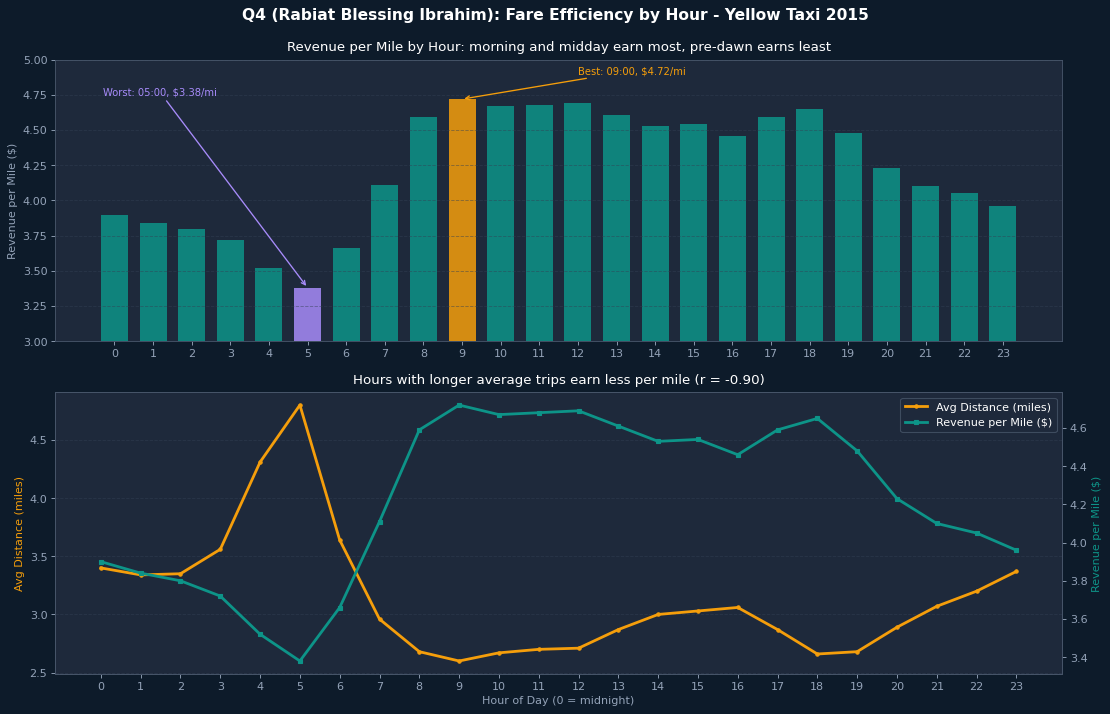

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
fig.suptitle('Q4 (Rabiat Blessing Ibrahim): Fare Efficiency by Hour - Yellow Taxi 2015',
             fontsize=14, fontweight='bold', color=WHITE, y=0.99)

ax1 = axes[0]
bh, wh = int(best['hour']), int(worst['hour'])
bar_colors = [AMBER if h==bh else PURPLE if h==wh else TEAL for h in df_q4['hour']]
ax1.bar(df_q4['hour'], df_q4['revenue_per_mile'], color=bar_colors, alpha=0.85, width=0.7)
ax1.set_title('Revenue per Mile by Hour: morning and midday earn most, pre-dawn earns least', fontsize=12, color=WHITE, pad=8)
ax1.set_ylabel('Revenue per Mile ($)', color=MUTED)
ax1.set_xticks(range(24)); ax1.grid(True, axis='y'); ax1.set_ylim(3, 5)
ax1.annotate(f'Best: {bh:02d}:00, ${best["revenue_per_mile"]:.2f}/mi',
             xy=(bh, best['revenue_per_mile']), xytext=(bh+3, 4.9), color=AMBER, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.2))
ax1.annotate(f'Worst: {wh:02d}:00, ${worst["revenue_per_mile"]:.2f}/mi',
             xy=(wh, worst['revenue_per_mile']), xytext=(-0.3, 4.75), color=PURPLE, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=PURPLE, lw=1.2))

ax2 = axes[1]
ax2b = ax2.twinx()
ax2b.tick_params(colors=MUTED); ax2b.spines['right'].set_color('#475569')
l1, = ax2.plot(df_q4['hour'], df_q4['avg_distance'], color=AMBER, lw=2.5, marker='o', ms=3, label='Avg Distance (miles)')
l2, = ax2b.plot(df_q4['hour'], df_q4['revenue_per_mile'], color=TEAL, lw=2.5, marker='s', ms=3, label='Revenue per Mile ($)')
ax2.set_title(f'Hours with longer average trips earn less per mile (r = {corr:.2f})', fontsize=12, color=WHITE, pad=8)
ax2.set_ylabel('Avg Distance (miles)', color=AMBER)
ax2b.set_ylabel('Revenue per Mile ($)', color=TEAL)
ax2.set_xlabel('Hour of Day (0 = midnight)', color=MUTED)
ax2.set_xticks(range(24)); ax2.grid(True, axis='y')
ax2.legend([l1,l2],[l1.get_label(),l2.get_label()],
           facecolor=PANEL, edgecolor='#475569', labelcolor=WHITE)

plt.tight_layout()
plt.savefig('query4_rabiat.png', dpi=150, bbox_inches='tight', facecolor=NAVY)
plt.show()


---
# JENNIFER FLORA BASTIAN - Queries 5 & 6
---
## Query 5: Solo vs Group Rider Demand by Hour
**Business Question:** Which hours are most popular for solo vs group taxi trips?
```sql
SELECT
  EXTRACT(HOUR FROM pickup_datetime) AS hour,
  CASE
    WHEN passenger_count = 1 THEN 'Solo Rider'
    ELSE 'Group Rider'
  END AS rider_type,
  COUNT(*) AS trip_count,
  ROUND(AVG(fare_amount), 2) AS avg_fare
FROM `bigquery-public-data.new_york.tlc_yellow_trips_2015`
WHERE fare_amount > 0
  AND passenger_count BETWEEN 1 AND 6
GROUP BY hour, rider_type
ORDER BY hour, rider_type;
```

In [10]:
q5_data = """hour,rider_type,trip_count,avg_fare
0,Group Rider,1783374,13.35
0,Solo Rider,3797376,13.32
1,Group Rider,1311085,13.0
1,Solo Rider,2809285,12.92
2,Group Rider,959876,12.96
2,Solo Rider,2065660,12.76
3,Group Rider,694333,13.62
3,Solo Rider,1509399,14.33
4,Group Rider,491692,15.8
4,Solo Rider,1153193,15.06
5,Group Rider,376293,17.9
5,Solo Rider,1153178,15.8
6,Group Rider,716556,14.81
6,Solo Rider,2543085,12.97
7,Group Rider,1263085,13.17
7,Solo Rider,4142427,11.94
8,Group Rider,1615571,13.05
8,Solo Rider,4946263,12.11
9,Group Rider,1697298,13.03
9,Solo Rider,5031810,12.1
10,Group Rider,1805206,13.22
10,Solo Rider,4831144,12.22
11,Group Rider,1961273,13.35
11,Solo Rider,4935259,12.51
12,Group Rider,2094831,13.44
12,Solo Rider,5113083,12.51
13,Group Rider,2129202,13.91
13,Solo Rider,5049269,13.02
14,Group Rider,2219443,14.47
14,Solo Rider,5183763,13.32
15,Group Rider,2167043,14.56
15,Solo Rider,4906290,13.51
16,Group Rider,1918610,14.34
16,Solo Rider,4254726,13.44
17,Group Rider,2251514,13.75
17,Solo Rider,5069591,12.95
18,Group Rider,2648413,12.81
18,Solo Rider,6097081,12.24
19,Group Rider,2752431,12.26
19,Solo Rider,6262970,11.94
20,Group Rider,2598436,12.38
20,Solo Rider,5914869,12.2
21,Group Rider,2668222,12.67
21,Solo Rider,5797979,12.58
22,Group Rider,2630950,13.01
22,Solo Rider,5521748,13.02
23,Group Rider,2297138,13.42
23,Solo Rider,4835832,13.5"""

df_q5 = pd.read_csv(io.StringIO(q5_data))
df_solo  = df_q5[df_q5['rider_type']=='Solo Rider'].set_index('hour')
df_group = df_q5[df_q5['rider_type']=='Group Rider'].set_index('hour')
hours = list(range(24))

total_solo  = df_solo['trip_count'].sum()
total_group = df_group['trip_count'].sum()
total_q5    = total_solo + total_group

print(f'Solo Riders : {total_solo/total_q5*100:.1f}% - {total_solo:,.0f} trips | avg fare ${df_solo["avg_fare"].mean():.2f}')
print(f'Group Riders: {total_group/total_q5*100:.1f}% - {total_group:,.0f} trips | avg fare ${df_group["avg_fare"].mean():.2f}')
print(f'Peak solo hour  : {df_solo["trip_count"].idxmax()}:00 - {df_solo["trip_count"].max():,} trips')
print(f'Peak group hour : {df_group["trip_count"].idxmax()}:00 - {df_group["trip_count"].max():,} trips')

Solo Riders : 70.5% - 102,925,280 trips | avg fare $13.01
Group Riders: 29.5% - 43,051,875 trips | avg fare $13.68
Peak solo hour  : 19:00 - 6,262,970 trips
Peak group hour : 19:00 - 2,752,431 trips


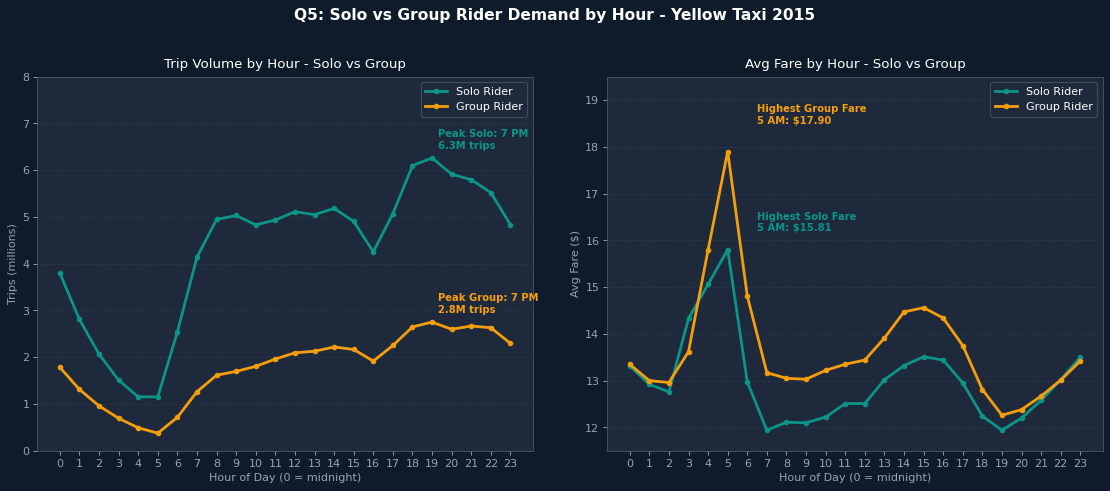

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Q5: Solo vs Group Rider Demand by Hour - Yellow Taxi 2015',
             fontsize=14, fontweight='bold', color=WHITE, y=1.02)

# Trip volume by hour
ax1 = axes[0]
ax1.set_ylim(0, 8)
ax1.plot(hours, df_solo['trip_count']/1e6,  color=TEAL,  lw=2.5, marker='o', ms=4, label='Solo Rider')
ax1.plot(hours, df_group['trip_count']/1e6, color=AMBER, lw=2.5, marker='o', ms=4, label='Group Rider')
ax1.set_title('Trip Volume by Hour - Solo vs Group', fontsize=12, color=WHITE, pad=8)
ax1.set_ylabel('Trips (millions)', color=MUTED)
ax1.set_xlabel('Hour of Day (0 = midnight)', color=MUTED)
ax1.legend(facecolor=PANEL, edgecolor='#475569', labelcolor=WHITE)
ax1.grid(True, axis='y')
ax1.set_xticks(hours)
ax1.tick_params(colors=MUTED)
ax1.text(19.3, df_solo.loc[19,'trip_count']/1e6 + 0.2,
         'Peak Solo: 7 PM\n6.3M trips',
         color=TEAL, fontsize=9, fontweight='bold')
ax1.text(19.3, df_group.loc[19,'trip_count']/1e6 + 0.2,
         'Peak Group: 7 PM\n2.8M trips',
         color=AMBER, fontsize=9, fontweight='bold')

# Avg fare by hour
ax2 = axes[1]
ax2.plot(hours, df_solo['avg_fare'],  color=TEAL,  lw=2.5, marker='o', ms=4, label='Solo Rider')
ax2.plot(hours, df_group['avg_fare'], color=AMBER, lw=2.5, marker='o', ms=4, label='Group Rider')
ax2.set_title('Avg Fare by Hour - Solo vs Group', fontsize=12, color=WHITE, pad=8)
ax2.set_ylabel('Avg Fare ($)', color=MUTED)
ax2.set_xlabel('Hour of Day (0 = midnight)', color=MUTED)
ax2.legend(facecolor=PANEL, edgecolor='#475569', labelcolor=WHITE)
ax2.grid(True, axis='y')
ax2.set_xticks(hours)
ax2.tick_params(colors=MUTED)
ax2.set_ylim(11.5, 19.5)
ax2.text(6.5, 18.5,
         'Highest Group Fare\n5 AM: $17.90',
         color=AMBER, fontsize=9, fontweight='bold')
ax2.text(6.5, 16.2,
         'Highest Solo Fare\n5 AM: $15.81',
         color=TEAL, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('query5.png', dpi=150, bbox_inches='tight', facecolor=NAVY)
plt.show()

---
## Query 6: Weekday vs Weekend Trip Patterns
**Business Question:** How do weekday and weekend taxi trips differ in fare, distance, and tipping behaviour?
```sql
SELECT
  CASE
    WHEN EXTRACT(DAYOFWEEK FROM pickup_datetime) IN (1, 7) THEN 'Weekend'
    ELSE 'Weekday'
  END AS day_type,
  COUNT(*) AS trip_count,
  ROUND(AVG(trip_distance), 2) AS avg_distance,
  ROUND(AVG(fare_amount), 2) AS avg_fare,
  ROUND(AVG(tip_amount), 2) AS avg_tip
FROM `bigquery-public-data.new_york.tlc_yellow_trips_2015`
WHERE fare_amount > 0
  AND trip_distance > 0
  AND trip_distance <= 50
GROUP BY day_type
ORDER BY day_type;
```

In [12]:
q6_data = """day_type,trip_count,avg_distance,avg_fare,avg_tip
Weekday,103003072,2.96,12.99,1.76
Weekend,42110062,3.05,12.60,1.64"""

df_q6 = pd.read_csv(io.StringIO(q6_data))

print('Query 6 Results:')
print(df_q6.to_string(index=False))
print()
print(f'Weekday trips : {df_q6.loc[0,"trip_count"]/1e6:.1f}M - avg fare ${df_q6.loc[0,"avg_fare"]:.2f} | avg distance {df_q6.loc[0,"avg_distance"]:.2f} mi')
print(f'Weekend trips : {df_q6.loc[1,"trip_count"]/1e6:.1f}M - avg fare ${df_q6.loc[1,"avg_fare"]:.2f} | avg distance {df_q6.loc[1,"avg_distance"]:.2f} mi')
print(f'Weekend fare premium : ${df_q6.loc[1,"avg_fare"]-df_q6.loc[0,"avg_fare"]:.2f} vs weekday')
print(f'Weekend tip premium  : ${df_q6.loc[1,"avg_tip"]-df_q6.loc[0,"avg_tip"]:.2f} vs weekday')
print()
print('NOTE: Weekday avg fare ($12.99) is slightly higher than weekend ($12.60).')
print('Weekend trips are slightly longer (3.05mi vs 2.96mi) but earn less per trip.')

Query 6 Results:
day_type  trip_count  avg_distance  avg_fare  avg_tip
 Weekday   103003072          2.96     12.99     1.76
 Weekend    42110062          3.05     12.60     1.64

Weekday trips : 103.0M - avg fare $12.99 | avg distance 2.96 mi
Weekend trips : 42.1M - avg fare $12.60 | avg distance 3.05 mi
Weekend fare premium : $-0.39 vs weekday
Weekend tip premium  : $-0.12 vs weekday

NOTE: Weekday avg fare ($12.99) is slightly higher than weekend ($12.60).
Weekend trips are slightly longer (3.05mi vs 2.96mi) but earn less per trip.


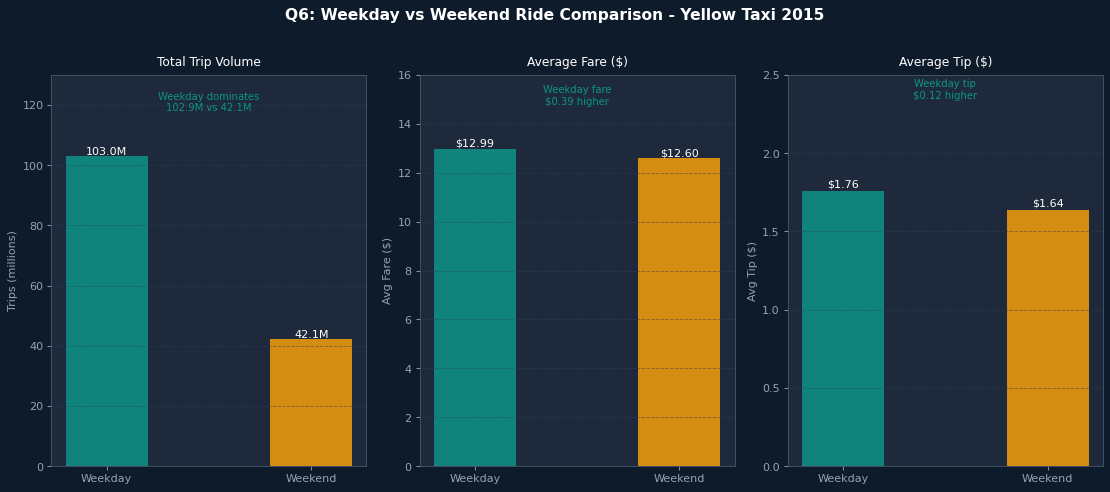

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 6))
fig.suptitle('Q6: Weekday vs Weekend Ride Comparison - Yellow Taxi 2015',
             fontsize=14, fontweight='bold', color=WHITE, y=1.02)

categories = ['Weekday', 'Weekend']
colors = [TEAL, AMBER]

# Trip count
axes[0].bar(categories, df_q6['trip_count']/1e6, color=colors, alpha=0.85, width=0.4)
axes[0].set_title('Total Trip Volume', fontsize=11, color=WHITE, pad=8)
axes[0].set_ylabel('Trips (millions)', color=MUTED)
axes[0].grid(True, axis='y')
axes[0].set_ylim(0, 130)
axes[0].tick_params(colors=MUTED)
for bar, val in zip(axes[0].patches, df_q6['trip_count']/1e6):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                 f'{val:.1f}M', ha='center', fontsize=10, color=WHITE)
axes[0].text(0.5, 118,
             'Weekday dominates\n102.9M vs 42.1M',
             ha='center', fontsize=9, color=TEAL)

# Avg fare
axes[1].bar(categories, df_q6['avg_fare'], color=colors, alpha=0.85, width=0.4)
axes[1].set_title('Average Fare ($)', fontsize=11, color=WHITE, pad=8)
axes[1].set_ylabel('Avg Fare ($)', color=MUTED)
axes[1].grid(True, axis='y')
axes[1].set_ylim(0, 16)
axes[1].tick_params(colors=MUTED)
for bar, val in zip(axes[1].patches, df_q6['avg_fare']):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
                 f'${val:.2f}', ha='center', fontsize=10, color=WHITE)
axes[1].text(0.5, 14.8,
             'Weekday fare\n$0.39 higher',
             ha='center', fontsize=9, color=TEAL)

# Avg tip
axes[2].bar(categories, df_q6['avg_tip'], color=colors, alpha=0.85, width=0.4)
axes[2].set_title('Average Tip ($)', fontsize=11, color=WHITE, pad=8)
axes[2].set_ylabel('Avg Tip ($)', color=MUTED)
axes[2].grid(True, axis='y')
axes[2].set_ylim(0, 2.5)
axes[2].tick_params(colors=MUTED)
for bar, val in zip(axes[2].patches, df_q6['avg_tip']):
    axes[2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
                 f'${val:.2f}', ha='center', fontsize=10, color=WHITE)
axes[2].text(0.5, 2.35,
             'Weekday tip\n$0.12 higher',
             ha='center', fontsize=9, color=TEAL)

plt.tight_layout()
plt.savefig('query6.png', dpi=150, bbox_inches='tight', facecolor=NAVY)
plt.show()

---
## Group 8 - Combined Findings Summary

In [14]:
print('=' * 65)
print('  GROUP 8 - COMBINED FINDINGS SUMMARY')
print('  ALY 6110 | Northeastern University | Prof. Shamseddini')
print('  Dataset: bigquery-public-data.new_york.tlc_yellow_trips_2015')
print('  Total records analyzed: 146M+ trips')
print('=' * 65)
print()
print('HAONAN ZHANG')
print('-' * 40)
peak_m   = months[df_q1['trip_count'].idxmax()]
low_m    = months[df_q1['trip_count'].idxmin()]
h1_trips = df_q1.iloc[:6]['trip_count'].sum()
h2_trips = df_q1.iloc[6:]['trip_count'].sum()
print(f'Q1: Peak in {peak_m} ({df_q1["trip_count"].max()/1e6:.1f}M trips, ${df_q1["total_revenue"].max()/1e6:.1f}M revenue).')
print(f'    Lowest in {low_m} ({df_q1["trip_count"].min()/1e6:.1f}M trips).')
print(f'    H1: {h1_trips/1e6:.1f}M trips vs H2: {h2_trips/1e6:.1f}M - clear summer/fall decline.')
print(f'    Avg trip value rose from ${df_q1["avg_trip_total"].min():.2f} to ${df_q1["avg_trip_total"].max():.2f}.')
print(f'Q2: Tip % rises from {df_q2["avg_tip_percentage"].iloc[0]:.1f}% (<1mi) to {df_q2["avg_tip_percentage"].iloc[3]:.1f}% (10+mi).')
print(f'    Very long trips earn ${df_q2["avg_tip"].iloc[3]:.2f} avg tip - {df_q2["avg_tip"].iloc[3]/df_q2["avg_tip"].iloc[0]:.1f}x more than short trips.')
print(f'    Medium 1-3mi trips are the most common: {df_q2["trip_count"].iloc[1]/1e6:.1f}M (50% of all trips).')
print(f'    Data quality note: avg_distance=211mi for 10+ group - outlier rows present.')
print()
print('RABIAT BLESSING IBRAHIM')
print('-' * 40)
print(f'Q3: Card = {total_card/total*100:.0f}% of trips, avg fare ${card_fare:.2f}.')
print(f'    Cash = {total_cash/total*100:.0f}%, avg fare ${cash_fare:.2f}.')
print(f'    Card payers pay ${card_fare-cash_fare:.2f} more per trip (trip-weighted).')
print(f'    Highest tips at 5 AM (${df_card.loc[5,"avg_tip"]:.2f}), the hour with the highest card fares.')
print(f'    Cash tips are $0 across all hours - not recorded digitally.')
print(f'Q4: Most efficient: {int(best["hour"]):02d}:00 at ${best["revenue_per_mile"]:.2f}/mile.')
print(f'    Least efficient: {int(worst["hour"]):02d}:00 at ${worst["revenue_per_mile"]:.2f}/mile.')
print(f'    Best and worst hours differ by ${best["revenue_per_mile"]-worst["revenue_per_mile"]:.2f} per mile.')
print(f'    Hours with longer average trips earn less per mile (r = {corr:.2f}).')
print()
print('JENNIFER FLORA BASTIAN')
print('-' * 40)
print(f'Q5: Solo riders make up {total_solo/total_q5*100:.0f}% of all trips - {total_solo/1e6:.1f}M trips.')
print(f'    Group riders account for {total_group/total_q5*100:.0f}% - {total_group/1e6:.1f}M trips.')
print(f'    Solo riders avg fare: ${df_solo["avg_fare"].mean():.2f} vs Group riders: ${df_group["avg_fare"].mean():.2f}.')
print(f'    Peak solo hour  : {df_solo["trip_count"].idxmax()}:00 - {df_solo["trip_count"].max()/1e6:.1f}M trips.')
print(f'    Peak group hour : {df_group["trip_count"].idxmax()}:00 - {df_group["trip_count"].max()/1e6:.1f}M trips.')
print(f'Q6: Weekday trips: {df_q6.loc[0,"trip_count"]/1e6:.1f}M | avg fare ${df_q6.loc[0,"avg_fare"]:.2f} | avg distance {df_q6.loc[0,"avg_distance"]:.2f} mi.')
print(f'    Weekend trips: {df_q6.loc[1,"trip_count"]/1e6:.1f}M | avg fare ${df_q6.loc[1,"avg_fare"]:.2f} | avg distance {df_q6.loc[1,"avg_distance"]:.2f} mi.')
print(f'    Weekday fare premium: ${df_q6.loc[0,"avg_fare"]-df_q6.loc[1,"avg_fare"]:.2f} more than weekend.')
print(f'    Weekday tip premium : ${df_q6.loc[0,"avg_tip"]-df_q6.loc[1,"avg_tip"]:.2f} more than weekend.')
print()
print('CROSS-QUERY INSIGHT')
print('-' * 40)
print('Q2 and Q4 together tell a consistent story: longer trips earn')
print('more tip dollars (Q2), while hours with longer trips earn less')
print(f'revenue per mile (Q4, r = {corr:.2f} across hours). Short')
print('urban trips are the most efficient for drivers, while long')
print('trips are more appreciated by passengers (higher tip %).')
print('Q5 and Q6 extend this: solo riders dominate volume at 70.5%')
print('of all trips, but group riders pay a higher avg fare per trip')
print(f'(${df_group["avg_fare"].mean():.2f} vs ${df_solo["avg_fare"].mean():.2f}).')
print('Weekday trips are more frequent (103.0M vs 42.1M) and generate')
print('higher fares and tips than weekends, confirming that commuter')
print('demand drives the majority of NYC yellow taxi revenue.')
print('=' * 65)

  GROUP 8 - COMBINED FINDINGS SUMMARY
  ALY 6110 | Northeastern University | Prof. Shamseddini
  Dataset: bigquery-public-data.new_york.tlc_yellow_trips_2015
  Total records analyzed: 146M+ trips

HAONAN ZHANG
----------------------------------------
Q1: Peak in Mar (13.3M trips, $216.2M revenue).
    Lowest in Aug (11.1M trips).
    H1: 77.1M trips vs H2: 69.0M - clear summer/fall decline.
    Avg trip value rose from $15.12 to $16.53.
Q2: Tip % rises from 8.9% (<1mi) to 10.1% (10+mi).
    Very long trips earn $6.05 avg tip - 8.2x more than short trips.
    Medium 1-3mi trips are the most common: 72.5M (50% of all trips).
    Data quality note: avg_distance=211mi for 10+ group - outlier rows present.

RABIAT BLESSING IBRAHIM
----------------------------------------
Q3: Card = 63% of trips, avg fare $13.48.
    Cash = 37%, avg fare $12.01.
    Card payers pay $1.47 more per trip (trip-weighted).
    Highest tips at 5 AM ($3.65), the hour with the highest card fares.
    Cash tips are $